### Exercice 18 — Courbes d'apprentissage et diagnostic

In [14]:
import numpy as np

import pandas as pd

from sklearn.preprocessing import LabelEncoder

from sklearn.linear_model import LogisticRegression 

from sklearn.model_selection import train_test_split , learning_curve

import matplotlib.pyplot as plt

### Utilisation du dataset de ex7

In [15]:
n = 500

df = pd.DataFrame({

    "age": np.random.randint(18, 76, n),

    "revenu_annuel": np.random.normal(

        loc=40000,

        scale=12000,

        size=n

    ).clip(10000, 100000).round(0),

    "anciennete_client_mois": np.random.randint(0, 241, n),

    "nb_produits_actuels": np.random.randint(0, 7, n),

    "score_credit": np.random.uniform(300, 850, n).round(0)
})

credit_norm = (df["score_credit"] - 300) / (850 - 300)

anciennete_norm = (

    df["anciennete_client_mois"] / 240

)

score_souscription = (

    0.6 * credit_norm

    + 0.4 * anciennete_norm

)

seuil = score_souscription.quantile(0.70)

df["a_souscrit"] = np.where(

    score_souscription >= seuil,

    "oui",
    
    "non"
)

encoder =  LabelEncoder()

df["a_souscrit"] =  encoder.fit_transform(df["a_souscrit"])

df

,age,revenu_annuel,anciennete_client_mois,nb_produits_actuels,score_credit,a_souscrit
0,45,46923.0,215,1,726.0,1
1,19,43596.0,143,5,452.0,0
2,30,40768.0,222,5,800.0,1
3,37,30689.0,1,5,745.0,0
4,74,45362.0,138,1,645.0,0
...,...,...,...,...,...,...
495,74,29352.0,185,0,610.0,1
496,49,23244.0,60,2,716.0,0
497,22,20596.0,78,2,720.0,0
498,60,53822.0,163,0,503.0,0


### Sepation du train et du test

In [16]:
x = df.drop("a_souscrit",axis=1)

y =  df["a_souscrit"]

x_train , x_test , y_train , y_test = train_test_split(x, y, test_size=0.25) 

### Entrainement du model 

In [17]:
model = LogisticRegression(max_iter=1000)

model.fit(x_train,y_train)

model.score(x_train,y_train)

pred = model.predict(x_test)

model.score(x_test,y_test)


0.992

### Utilisation de Learning_curve

In [18]:
n , train_score , val_score = learning_curve(model , x_train , y_train , train_sizes=np.linspace(0.1, 1.0, 10) , cv=5)

### Tracage de la courbe l'aprentissage

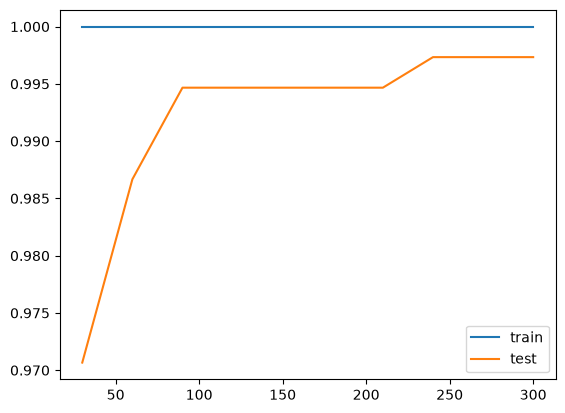

In [21]:
fig , ax =  plt.subplots()

ax.plot(n,train_score.mean(axis=1),label="train")

ax.plot(n,val_score.mean(axis=1),label="test")

ax.legend()

La courbe d'apprentissage montre que le modèle LogisticRegression obtient un score d'entraînement de 100 % et un score de validation compris entre 97 % et 99,7 %. Les deux performances sont élevées et l'écart entre elles diminue lorsque la quantité de données augmente. Le modèle présente donc une très bonne capacité de généralisation et ne souffre pas d'un surapprentissage important. Aucune correction majeure ne semble nécessaire, mais une régularisation plus forte peut être testée afin de vérifier si elle améliore encore les performances.